# Final report — supporting notebook

Reproduces every number and figure in `reports/2026-11-02_final-report.md`.
The pipeline scripts are the source of truth; this notebook runs them end to end
and then displays the headline tables the report quotes.

Prerequisites: `pip install -r requirements.txt && pip install -e .`, then
`make fetch cache` (raw CSVs + parquet cache). Runtime ≈ 1 minute.

Committed after restart-and-run-all (repo convention).

In [1]:
import sys
from pathlib import Path

from oscar_cs.paths import ROOT

sys.path.insert(0, str(ROOT / 'scripts'))  # for build_rx_model's figure import
print(ROOT)

/home/user/oscar-case-study-2


## 1. Characterization (requirement 1) — build + stats dump

In [2]:
script = str(ROOT / 'scripts' / 'build_health_status.py')
%run -i {script}

{
  "policy": {
    "window": [
      "2015-09-01",
      "2018-06-04"
    ],
    "shape_rule": "one_off = 1 date; episode = >=2 dates, span <= 180d; chronic = span > 180d (injuries/infections capped at episode)",
    "tier_rule": "head/tail breaks on positives; zero its own bin; flags above p99",
    "excluded_buckets": [
      "admin (Z-codes)",
      "immunizations",
      "residual",
      "unmapped"
    ]
  },
  "exclusions": {
    "rows_total": 1919983,
    "members_total": 245166,
    "rows_null_date": 24,
    "rows_pre_window": 201,
    "rows_post_window": 6,
    "rows_clean": 1919752,
    "members_clean": 245151,
    "members_lost_by_cleaning": 15
  },
  "mapping": {
    "bucket_rows": {
      "admin": 250060,
      "condition": 1509935,
      "immunizations": 29164,
      "residual": 31625,
      "symptoms": 96978,
      "unmapped": 1990
    },
    "bucket_members": {
      "admin": 129591,
      "condition": 216199,
      "immunizations": 22386,
      "residual": 16155,
    

## 2. Report figures 1–2

In [3]:
script = str(ROOT / 'scripts' / 'report_figures.py')
%run -i {script}

wrote 2 figures to /home/user/oscar-case-study-2/reports/figures (stem 2026-11-02_final)


## 3. Rx-only model (requirement 2) — train, evaluate, score

In [4]:
script = str(ROOT / 'scripts' / 'build_rx_model.py')
%run -i {script}

{
  "population": {
    "modeled_members": 192830,
    "train_members": 154264,
    "test_members": 38566,
    "rx_only_scored": 37583
  },
  "conditions": [
    {
      "condition": "Hypertension",
      "train_positives": 4104,
      "test_prevalence_pct": 2.71,
      "auroc": 0.942,
      "auprc": 0.357,
      "auprc_baseline": 0.0271,
      "top_positive_classes": [
        "Angiotensin Ii Receptor Ant-Ca Channel Blocker-Thiazides",
        "Angiotensin Ii Receptor Antag & Ca Channel Blocker Comb",
        "log1p_total_fills",
        "Ace Inhibitors & Thiazide/Thiazide-Like",
        "Ace Inhibitor & Calcium Channel Blocker Combinations"
      ]
    },
    {
      "condition": "Diseases of female genital organs",
      "train_positives": 2645,
      "test_prevalence_pct": 1.73,
      "auroc": 0.835,
      "auprc": 0.19,
      "auprc_baseline": 0.0173,
      "top_positive_classes": [
        "Ulcer Drugs - Prostaglandins",
        "Hemostatics - Systemic",
        "Vaginal Anti-Inf

## 4. Headline tables quoted in the report

In [5]:
import json

import pandas as pd

from oscar_cs.paths import DATA_PROCESSED

stats = json.load(open(DATA_PROCESSED / 'health_status_stats.json'))
mix = pd.Series(stats['population']['member_mix']).rename('members')
mix_pct = (100 * mix / stats['population']['members_characterized']).round(1)
pd.DataFrame({'members': mix, 'pct': mix_pct})

,members,pct
one_off_only,101672,41.5
episodic,77192,31.5
chronic,37335,15.2
admin_or_unmapped_only,24011,9.8
symptom_only,4941,2.0


In [6]:
# tier cut points and sizes (head/tail breaks), p99 flags
display(pd.DataFrame(stats['tiers']['cuts']))
display(pd.DataFrame(stats['tiers']['tier_sizes']))
pd.Series(stats['tiers']['p99_flags'])

,dx,rx
cut1,7.83,11.69
cut2,20.85,31.86
p99,63.00,94.00


,dx,rx
none,37583,52321
low,177428,166859
med,47899,43223
high,19824,20331


dx_above_p99                    2439.0
rx_above_p99                    2270.0
high_utilizer_both               518.0
expected_both_if_independent      19.6
dtype: float64

In [7]:
# dx x rx tier contingency: members and lift vs independence
display(pd.DataFrame(stats['tiers']['contingency_members']))
pd.DataFrame(stats['tiers']['contingency_lift'])

,none,low,med,high
none,0,48895,3000,426
low,34820,105166,22374,4499
med,2424,19354,15153,6292
high,339,4013,7372,8607


,none,low,med,high
none,0.00,1.49,0.34,0.12
low,1.57,1.00,0.79,0.38
med,0.42,0.71,2.07,2.08
high,0.13,0.31,2.14,6.04


In [8]:
# top-20 conditions by members, split by shape
pd.DataFrame(stats['population']['top20_conditions_by_shape'])

,chapter,condition,chronic,episode,one_off,members_any,pct_members_any
0,Diseases of the respiratory system,Respiratory infections,0,20613,40608,61221,25.0
1,Diseases of the skin and subcutaneous tissue,Other skin disorders,2973,5586,19327,27886,11.4
2,Diseases of the nervous system and sense organs,Eye disorders,3431,5002,16749,25182,10.3
3,Diseases of the genitourinary system,Diseases of female genital organs,3436,6436,14940,24812,10.1
4,Diseases of the musculoskeletal system and con...,Other connective tissue disease,2264,6563,14179,23006,9.4
5,Diseases of the musculoskeletal system and con...,Non-traumatic joint disorders,2703,7693,12573,22969,9.4
6,Diseases of the circulatory system,Hypertension,5223,5762,11775,22760,9.3
7,Diseases of the respiratory system,Other lower respiratory disease,1652,4224,16088,21964,9.0
8,Diseases of the musculoskeletal system and con...,Spondylosis; intervertebral disc disorders; ot...,2818,8182,10622,21622,8.8
9,Diseases of the circulatory system,Diseases of the heart,2898,6860,11666,21424,8.7


In [9]:
# reinfection-trap cap + symptoms track
print(stats['reinfection_cap'])
print('symptom-track members:', stats['population']['members_with_symptom_track'],
      '| persistent:', stats['population']['members_symptoms_persistent'])
pd.Series(stats['population']['top10_symptoms_by_members']).rename('members')

{'pairs_capped_chronic_to_episode': 11091, 'pct_of_acute_only_pairs_capped': 8.88, 'top_capped_conditions': {'Respiratory infections': 8600, 'Sprains and strains': 429, 'Mycoses': 419, 'Skin and subcutaneous tissue infections': 382, 'Fractures': 254}}
symptom-track members: 50525 | persistent: 3491


Abdominal pain                                                                           19162
Other screening for suspected conditions (not mental disorders or infectious disease)    12381
Allergic reactions                                                                       11389
Malaise and fatigue                                                                       6581
Fever of unknown origin                                                                   4289
Nausea and vomiting                                                                       3516
Syncope                                                                                   1969
Lymphadenitis                                                                             1585
Shock                                                                                       78
Gangrene                                                                                    59
Name: members, dtype: int64

In [10]:
# per-condition model metrics with AUPRC lift over the prevalence baseline
mm = json.load(open(DATA_PROCESSED / 'rx_model_metrics.json'))
met = pd.DataFrame(mm['metrics']['conditions'])
met['auprc_lift'] = (met['auprc'] / met['auprc_baseline']).round(0).astype(int)
met[['condition', 'test_prevalence_pct', 'auroc', 'auprc', 'auprc_baseline', 'auprc_lift']]

,condition,test_prevalence_pct,auroc,auprc,auprc_baseline,auprc_lift
0,Hypertension,2.71,0.942,0.357,0.0271,13
1,Diseases of female genital organs,1.73,0.835,0.190,0.0173,11
2,Eye disorders,1.70,0.853,0.230,0.0170,14
3,Other skin disorders,1.41,0.866,0.184,0.0141,13
4,Diseases of the heart,1.52,0.908,0.327,0.0152,22
5,Spondylosis; intervertebral disc disorders; ot...,1.41,0.887,0.268,0.0141,19
6,Non-traumatic joint disorders,1.34,0.880,0.266,0.0134,20
7,Diabetes mellitus without complication,1.16,0.942,0.282,0.0116,24
8,Diseases of the urinary system,1.24,0.919,0.328,0.0124,26
9,Other connective tissue disease,1.10,0.855,0.109,0.0110,10


In [11]:
# rx-only scoring: expected chronic members + the antidiabetic rank check
from oscar_cs.db import connect_views

scores = pd.read_parquet(DATA_PROCESSED / 'rx_only_scores.parquet').set_index('member_id')
print('expected chronic members among the 37,583 rx-only (sum of probabilities):')
display(scores.sum().sort_values(ascending=False).round(0).astype(int).head(5))
con = connect_views()
bigu = con.execute("""
  select member_id from prescription_drugs
  where drug_class in ('Biguanides','Human Insulin','Insulin Analog','Diabetic Other')
    and try_cast(date_svc as date) between date '2015-09-01' and date '2018-06-04'
  group by member_id having count(*) >= 3""").df()['member_id']
dm_cols = ['Diabetes mellitus without complication', 'Diabetes mellitus with complications']
on_rx = scores.index.isin(set(bigu))
dm, rest = scores.loc[on_rx, dm_cols].max(axis=1), scores.loc[~on_rx, dm_cols].max(axis=1)
print(f'rx-only members with >=3 antidiabetic fills: {on_rx.sum():,}')
print(f'median predicted diabetes prob: {dm.median():.3f} vs {rest.median():.4f} '
      f'({dm.median() / rest.median():.0f}x)')

expected chronic members among the 37,583 rx-only (sum of probabilities):


Hypertension                         242
Eye disorders                        213
Diseases of female genital organs    210
Other skin disorders                 194
Non-traumatic joint disorders        128
dtype: int64

rx-only members with >=3 antidiabetic fills: 530
median predicted diabetes prob: 0.027 vs 0.0007 (40x)


## 5. Figures

2026-11-02_final_fig01_top_conditions.png


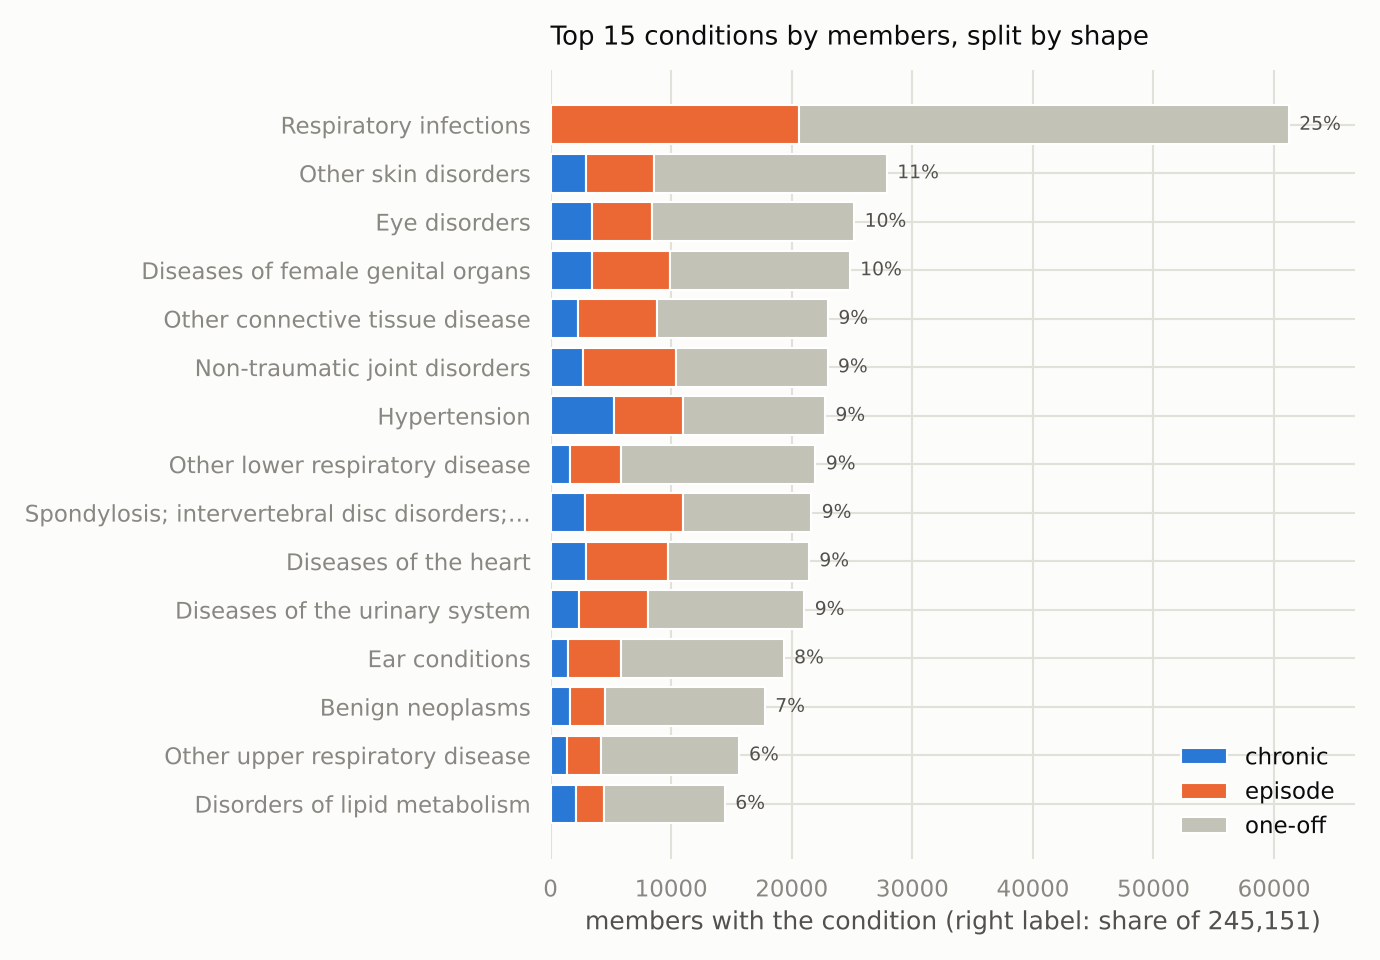

2026-11-02_final_fig02_tier_lift.png


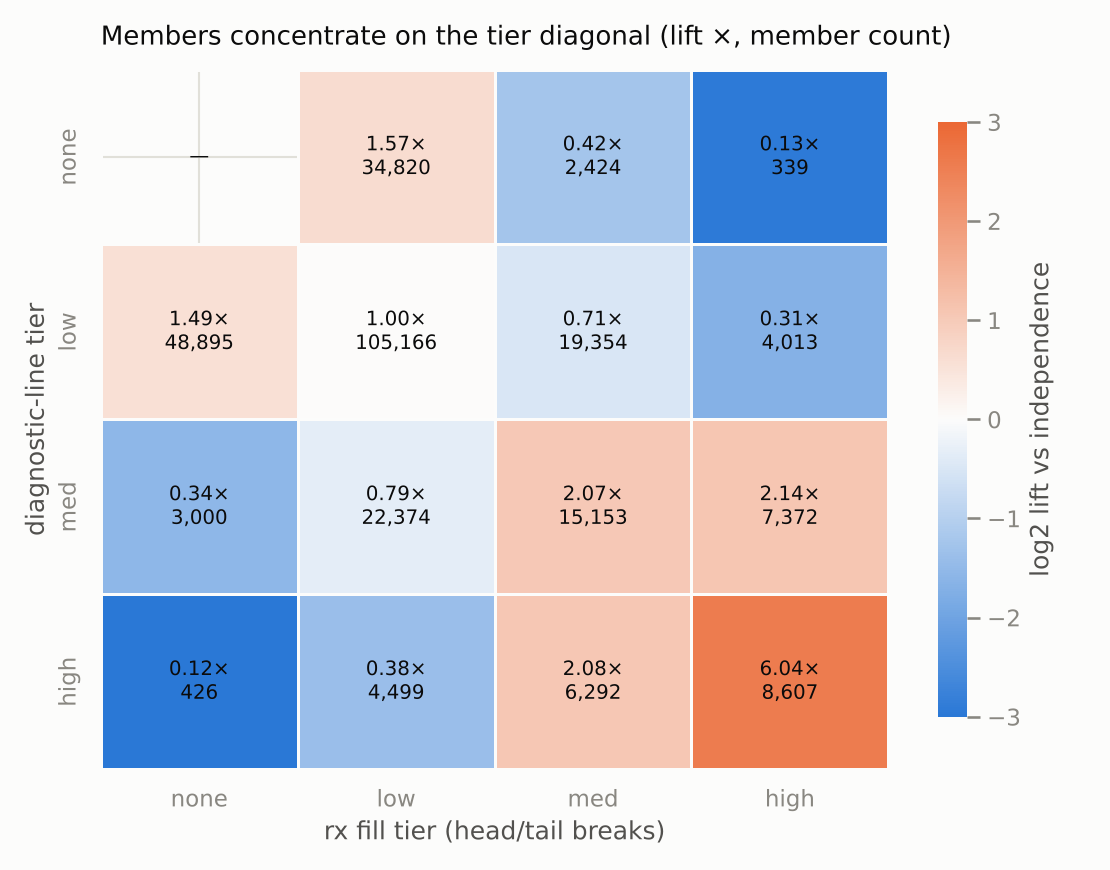

2026-11-02_final_fig03_rx_model_metrics.png


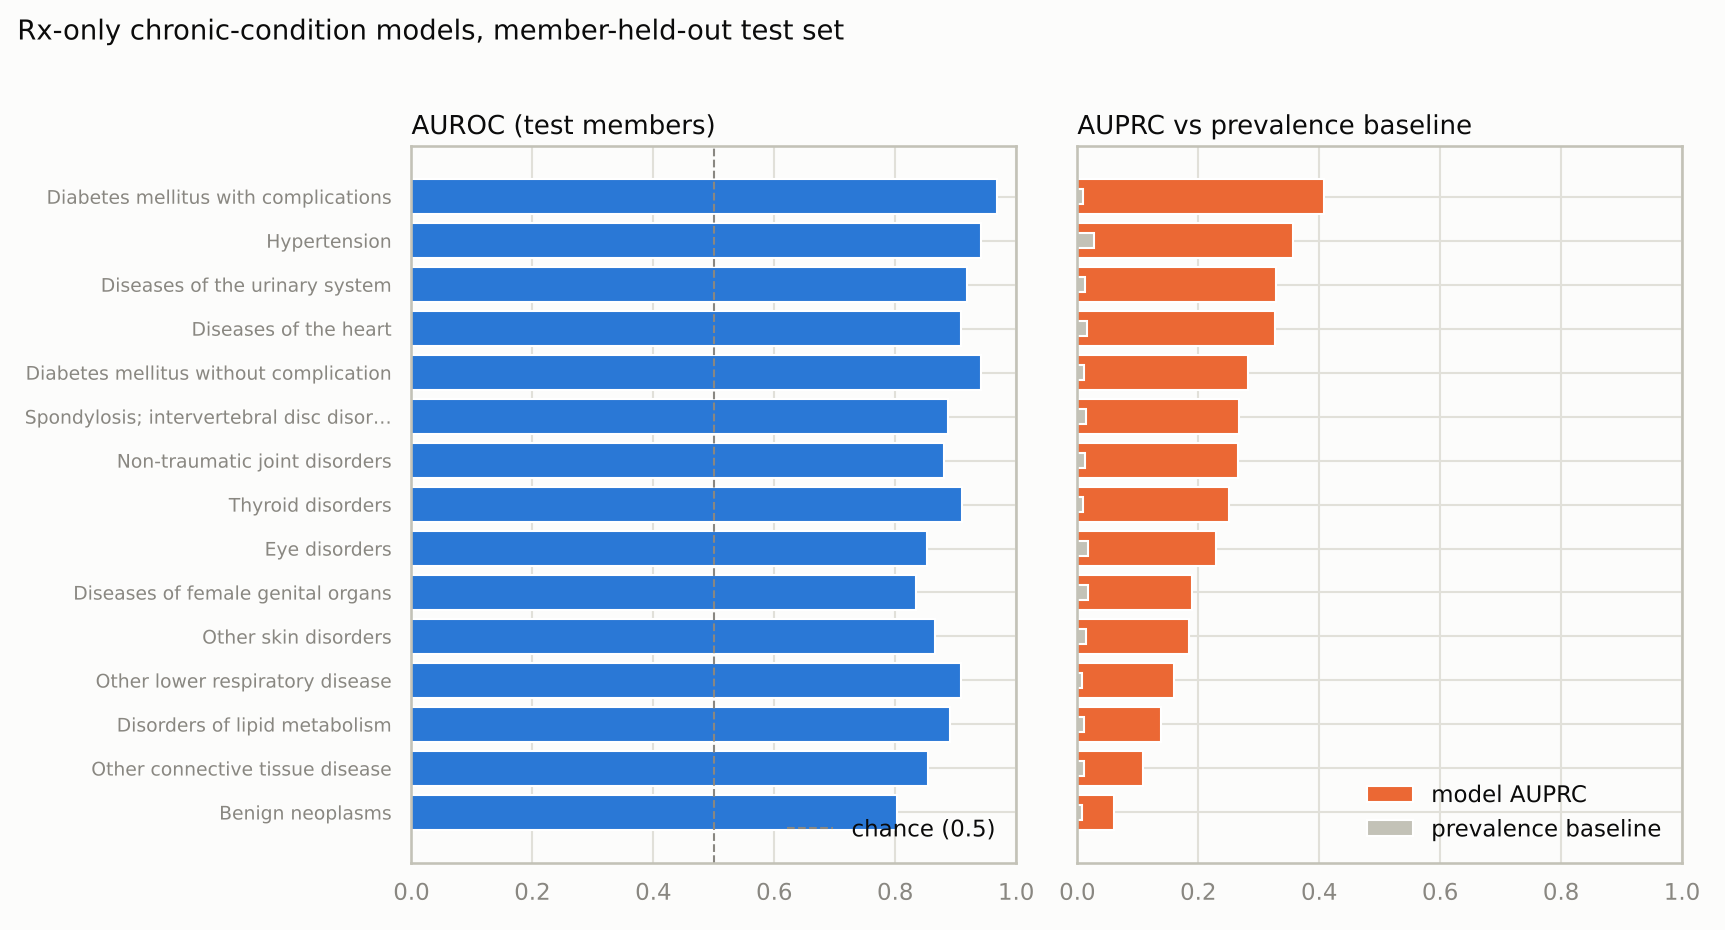

2026-11-02_final_fig04_calibration.png


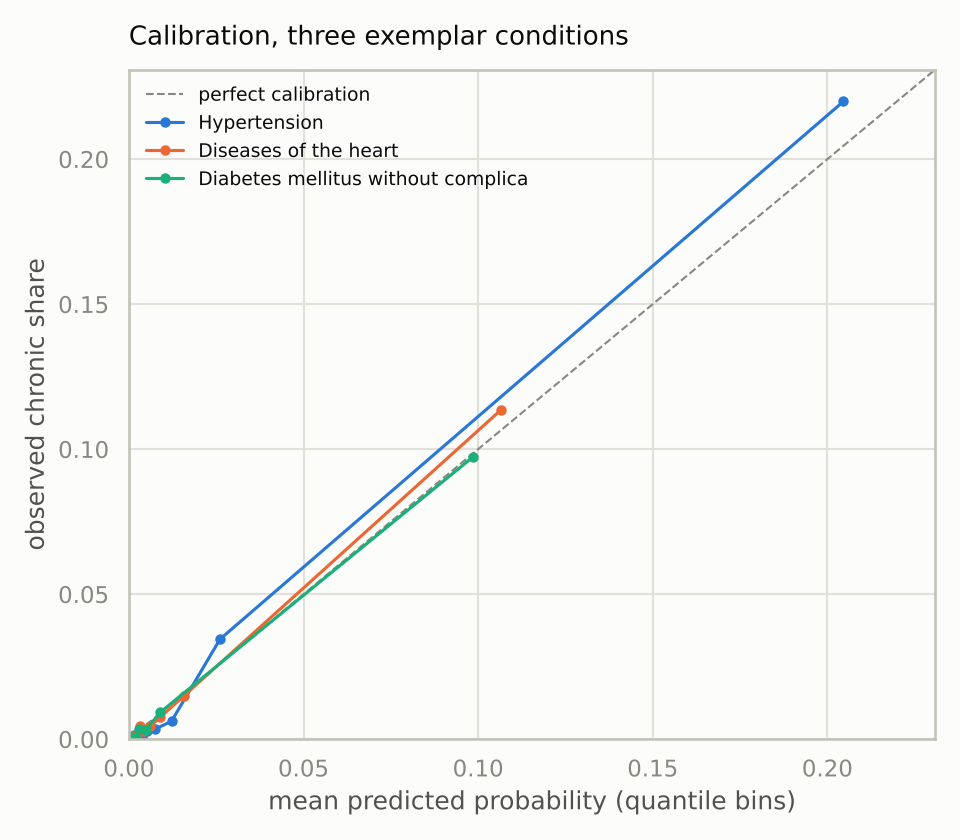

In [12]:
from IPython.display import Image, display

from oscar_cs.paths import FIGURES

for fig in sorted(FIGURES.glob('2026-11-02_final_fig*.png')):
    print(fig.name)
    display(Image(str(fig), width=820))